# Glyph Hallucination: How Diffusion Models Get Arabic Text Wrong

**Question.** When Stable Diffusion is asked to draw an Arabic word, how often does it write the correct letters, and what kinds of mistakes does it make?

**Plan**
1. Download an Arabic text corpus from Kaggle with `kagglehub` (no login needed) and build a word list.
2. Render each word cleanly with real Arabic fonts and check that the OCR can read it. Only words the OCR reads correctly are kept, so later errors come from the diffusion model and not from the OCR.
3. Generate images with Stable Diffusion 1.5 and read them back with OCR.
4. Measure the errors: character error rate (CER), exact match, images with no Arabic text, wrong letters that differ only by dots, and errors by letter position (isolated, initial, medial, final).
5. Fine-tune Stable Diffusion with LoRA on rendered Arabic words, then test again on **unseen** words.

**Runtime:** Colab with a T4 GPU (Runtime > Change runtime type > T4 GPU). The full run takes about 60 to 90 minutes with the default settings.

In [24]:
# 1. Install packages
!pip -q install -U kagglehub diffusers transformers accelerate peft easyocr arabic-reshaper python-bidi

/usr/local/lib/python3.13/dist-packages/diffusers/configuration_utils.py:172: FutureWarning: Accessing config attribute `__iter__` directly via 'DDPMScheduler' object attribute is deprecated. Please access '__iter__' over 'DDPMScheduler's config object instead, e.g. 'scheduler.config.__iter__'.
  deprecate("direct config name access", "1.0.0", deprecation_message, standard_warn=False)
/usr/local/lib/python3.13/dist-packages/diffusers/configuration_utils.py:172: FutureWarning: Accessing config attribute `__iter__` directly via 'StableDiffusionPipeline' object attribute is deprecated. Please access '__iter__' over 'StableDiffusionPipeline's config object instead, e.g. 'scheduler.config.__iter__'.
  deprecate("direct config name access", "1.0.0", deprecation_message, standard_warn=False)
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1645: FutureWarning: Accessing config attribute `__iter__` directly via 'UNet2DConditionModel' object attribute is deprecated. Please ac

In [25]:
# 2. Settings (change these if you want a faster or bigger run)
import os, random, numpy as np, torch

SEED          = 42
N_TEST_WORDS  = 60      # unseen words used for evaluation
N_TRAIN_WORDS = 400     # words used for LoRA training (never overlap with test words)
PROMPTS = [
    'a wooden sign with the Arabic word "{w}" written on it, photo',
    'a poster with the Arabic text "{w}" in large letters',
]
GEN_STEPS     = 25
GUIDANCE      = 7.5
IMG_SIZE      = 512
LORA_STEPS    = 1500
LORA_RANK     = 8
LORA_LR       = 1e-4
TRAIN_TEXT_ENCODER = True   # the CLIP text encoder knows little Arabic, so we adapt it too
OUT_DIR = '/content/glyph_hallucination'
os.makedirs(OUT_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)
assert device == 'cuda', 'Please switch the runtime to a GPU (T4).'

Device: cuda


## Helper functions: normalisation, letter positions, edit operations and error analysis

In [26]:
import re, unicodedata

AR_LETTERS = re.compile(r'[ء-ي]')
DIACRITICS = re.compile(r'[ً-ْٰـ]')   # harakat, dagger alef, tatweel
RIGHT_JOIN = set('اأإآدذرزوؤةى')   # letters that never join to the next letter
NON_JOIN = set('ء')
# letters that differ only by dots share the same skeleton
DOT_GROUPS = ['بتثني', 'جحخ', 'دذ', 'رز', 'سش', 'صض', 'طظ', 'عغ', 'فق', 'هة']
SKELETON = {ch: i for i, g in enumerate(DOT_GROUPS) for ch in g}

def normalize(text):
    """NFKC turns presentation forms into base letters; then unify common OCR variants."""
    t = unicodedata.normalize('NFKC', text or '')
    t = DIACRITICS.sub('', t)
    t = re.sub('[أإآٱ]', 'ا', t)
    t = t.replace('ى', 'ي')
    t = ''.join(ch for ch in t if not ch.isspace())
    return t

def arabic_only(text):
    return ''.join(AR_LETTERS.findall(text))

def arabic_ratio(text):
    t = ''.join(ch for ch in (text or '') if not ch.isspace())
    return len(AR_LETTERS.findall(t)) / len(t) if t else 0.0

def position_forms(word):
    """Contextual form of each letter: isolated / initial / medial / final."""
    forms = []
    for i, ch in enumerate(word):
        prev_ch = word[i - 1] if i > 0 else None
        next_ch = word[i + 1] if i + 1 < len(word) else None
        joins_prev = prev_ch is not None and prev_ch not in RIGHT_JOIN and prev_ch not in NON_JOIN and ch not in NON_JOIN
        joins_next = next_ch is not None and ch not in RIGHT_JOIN and ch not in NON_JOIN and next_ch not in NON_JOIN
        if joins_prev and joins_next: forms.append('medial')
        elif joins_prev: forms.append('final')
        elif joins_next: forms.append('initial')
        else: forms.append('isolated')
    return forms

def editops(a, b):
    """Levenshtein edit operations (op, i_in_a, j_in_b). Words are short, so plain DP is fine."""
    n, m = len(a), len(b)
    d = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1): d[i][0] = i
    for j in range(m + 1): d[0][j] = j
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            d[i][j] = min(d[i-1][j] + 1, d[i][j-1] + 1, d[i-1][j-1] + (a[i-1] != b[j-1]))
    ops, i, j = [], n, m
    while i > 0 or j > 0:
        if i > 0 and j > 0 and d[i][j] == d[i-1][j-1] + (a[i-1] != b[j-1]):
            if a[i-1] != b[j-1]: ops.append(('replace', i-1, j-1))
            i, j = i-1, j-1
        elif i > 0 and d[i][j] == d[i-1][j] + 1:
            ops.append(('delete', i-1, j)); i -= 1
        else:
            ops.append(('insert', i, j-1)); j -= 1
    return ops[::-1], d[n][m]

def analyse(gt_raw, ocr_raw):
    gt = normalize(gt_raw)
    ocr_full = normalize(ocr_raw)
    ocr = arabic_only(ocr_full)
    ops, dist = editops(gt, ocr)
    forms = position_forms(gt)
    res = {
        'gt': gt, 'ocr': ocr_full,
        'cer': min(dist / max(len(gt), 1), 1.0),
        'exact': int(ocr == gt),
        'no_arabic': int(len(ocr) == 0),
        'arabic_ratio': arabic_ratio(ocr_full),
        'n_sub': 0, 'n_del': 0, 'n_ins': 0, 'n_dot': 0,
        'n_chars': len(gt),
    }
    pos_err = {f: 0 for f in ['isolated', 'initial', 'medial', 'final']}
    pos_tot = {f: forms.count(f) for f in pos_err}
    for op, i, j in ops:
        if op == 'replace':
            res['n_sub'] += 1
            if gt[i] in SKELETON and ocr[j] in SKELETON and SKELETON[gt[i]] == SKELETON[ocr[j]]:
                res['n_dot'] += 1
            pos_err[forms[i]] += 1
        elif op == 'delete':
            res['n_del'] += 1
            pos_err[forms[i]] += 1
        else:
            res['n_ins'] += 1
    for f in pos_err:
        res[f'err_{f}'] = pos_err[f]
        res[f'tot_{f}'] = pos_tot[f]
    return res


# quick self-test
assert position_forms('كتاب') == ['initial', 'medial', 'final', 'isolated']
assert analyse('مدرسة', 'مدرشه')['n_dot'] == 2
print('helpers OK')

helpers OK


## Step 1. Build the word list from a Kaggle Arabic corpus

The dataset is *Arabic News Articles from Aljazeera.net* (`arhouati/arabic-news-articles-from-aljazeeranet`). It is public, so `kagglehub` downloads it without a login. If the download fails for any reason, a built-in list of common words is used so the notebook still runs.

In [27]:
import kagglehub, glob, collections, pandas as pd

FALLBACK_WORDS = '''كتاب مدرسة بيت باب شمس قمر ماء نور سلام مرحبا شكرا قلم ورقة مكتبة جامعة طالب معلم طريق سيارة
مدينة بحر جبل شجرة زهرة طعام خبز قهوة شاي حليب سوق مطعم فندق مستشفى صيدلية مطار قطار حديقة نافذة غرفة مطبخ
سماء نجمة ريح مطر ثلج صباح مساء ليل يوم شهر سنة وقت ساعة عمل علم فكر حب أمل صديق عائلة أم أب أخ أخت ولد بنت
رجل امرأة طفل قلب يد عين رأس وجه لون أحمر أخضر أزرق أبيض أسود كبير صغير جميل جديد قديم سعيد حرية عدالة وطن
تاريخ ثقافة فن موسيقى رياضة كرة لعبة هاتف حاسوب رسالة خريطة مفتاح ذهب فضة ملح سكر تفاح برتقال عنب ليمون نخلة
صحراء نهر جسر قرية مسجد شارع ميدان متحف مصنع بنك شركة سفر رحلة طائرة سفينة دراجة حصان جمل قطة كلب طائر سمك أسد'''.split()

STOP = set('''هذا هذه التي الذي الذين التى كانت يكون تكون وقال قالت الله عليه وكان لكن حيث بين حتى بعد قبل
خلال ضمن أيضا مثل منذ عند عليها فيها منها إلى على ذلك تلك كما وقد ولكن أكثر أمام الآن غير'''.split())

def build_word_list():
    try:
        path = kagglehub.dataset_download('arhouati/arabic-news-articles-from-aljazeeranet')
        print('Downloaded to', path)
        counter, read_bytes = collections.Counter(), 0
        for f in glob.glob(os.path.join(path, '**', '*'), recursive=True):
            if not os.path.isfile(f) or read_bytes > 60_000_000:
                continue
            ext = f.lower().rsplit('.', 1)[-1]
            try:
                if ext == 'csv':
                    df = pd.read_csv(f, dtype=str, on_bad_lines='skip', low_memory=False)
                    text = ' '.join(df.fillna('').astype(str).values.ravel())
                elif ext in ('txt', 'json', 'tsv'):
                    text = open(f, encoding='utf-8', errors='ignore').read()
                else:
                    continue
            except Exception as e:
                print('skip', f, e); continue
            read_bytes += len(text.encode('utf-8'))
            counter.update(re.findall(r'[\u0621-\u064A]+', text))
        words = [w for w, c in counter.most_common(20000)
                 if 4 <= len(w) <= 8 and w not in STOP and c >= 5]
        if len(words) < N_TEST_WORDS + 100:
            raise ValueError('too few words found')
        print(f'{len(words)} candidate words from Kaggle')
        return words, 'kaggle'
    except Exception as e:
        print('Kaggle download or parsing failed, using fallback list:', e)
        return FALLBACK_WORDS, 'fallback'

ALL_WORDS, WORD_SOURCE = build_word_list()
ALL_WORDS = list(dict.fromkeys(normalize(w) for w in ALL_WORDS))   # normalise and de-duplicate
print(WORD_SOURCE, len(ALL_WORDS), ALL_WORDS[:20])

Using Colab cache for faster access to the 'arabic-news-articles-from-aljazeeranet' dataset.
Downloaded to /kaggle/input/arabic-news-articles-from-aljazeeranet


/usr/local/lib/python3.13/dist-packages/diffusers/configuration_utils.py:172: FutureWarning: Accessing config attribute `__iter__` directly via 'DDPMScheduler' object attribute is deprecated. Please access '__iter__' over 'DDPMScheduler's config object instead, e.g. 'scheduler.config.__iter__'.
  deprecate("direct config name access", "1.0.0", deprecation_message, standard_warn=False)
/usr/local/lib/python3.13/dist-packages/diffusers/configuration_utils.py:172: FutureWarning: Accessing config attribute `__iter__` directly via 'StableDiffusionPipeline' object attribute is deprecated. Please access '__iter__' over 'StableDiffusionPipeline's config object instead, e.g. 'scheduler.config.__iter__'.
  deprecate("direct config name access", "1.0.0", deprecation_message, standard_warn=False)
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1645: FutureWarning: Accessing config attribute `__iter__` directly via 'UNet2DConditionModel' object attribute is deprecated. Please ac

17456 candidate words from Kaggle
kaggle 17383 ['كورونا', 'الجزيرة', 'المصدر', 'المتحدة', 'فيروس', 'اليوم', 'الرئيس', 'الحكومة', 'ترامب', 'العالم', 'الماضي', 'رئيس', 'يمكن', 'بشكل', 'العام', 'الولايات', 'الاميركي', 'الصين', 'بسبب', 'ايران']


## Step 2. Fonts, clean rendering and OCR check

Fonts come from the Google Fonts GitHub repository (open licence, no login). Arabic letters are joined with `arabic-reshaper` and put in visual order with `python-bidi`, so the rendering is correct even when Pillow has no complex-text support.

Fonts ready: ['Amiri', 'Scheherazade', 'Lateef', 'Tajawal', 'Tajawal-Bold', 'Harmattan', 'Mada', 'Cairo']


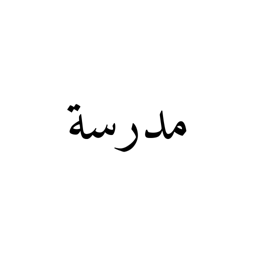

In [28]:
import urllib.request
from PIL import Image, ImageDraw, ImageFont, ImageFilter
import arabic_reshaper
from bidi.algorithm import get_display

FONT_URLS = {
    'Amiri':          'https://github.com/google/fonts/raw/main/ofl/amiri/Amiri-Regular.ttf',
    'Scheherazade':   'https://github.com/google/fonts/raw/main/ofl/scheherazadenew/ScheherazadeNew-Regular.ttf',
    'Lateef':         'https://github.com/google/fonts/raw/main/ofl/lateef/Lateef-Regular.ttf',
    'Tajawal':        'https://github.com/google/fonts/raw/main/ofl/tajawal/Tajawal-Regular.ttf',
    'Tajawal-Bold':   'https://github.com/google/fonts/raw/main/ofl/tajawal/Tajawal-Bold.ttf',
    'Harmattan':      'https://github.com/google/fonts/raw/main/ofl/harmattan/Harmattan-Regular.ttf',
    'Mada':           'https://github.com/google/fonts/raw/main/ofl/mada/Mada%5Bwght%5D.ttf',
    'Cairo':          'https://github.com/google/fonts/raw/main/ofl/cairo/Cairo%5Bslnt%2Cwght%5D.ttf',
}
FONT_DIR = os.path.join(OUT_DIR, 'fonts'); os.makedirs(FONT_DIR, exist_ok=True)
FONTS = {}
for name, url in FONT_URLS.items():
    dst = os.path.join(FONT_DIR, name + '.ttf')
    try:
        if not os.path.exists(dst):
            urllib.request.urlretrieve(url, dst)
        ImageFont.truetype(dst, 40)          # check that it loads
        FONTS[name] = dst
    except Exception as e:
        print('font skipped:', name, e)
if not FONTS:
    FONTS['DejaVu'] = '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf'
print('Fonts ready:', list(FONTS))

def visual_text(word):
    return get_display(arabic_reshaper.reshape(word))

def render_word(word, font_path, size=IMG_SIZE, bg=(255, 255, 255), fg=(0, 0, 0), font_px=None):
    img = Image.new('RGB', (size, size), bg)
    draw = ImageDraw.Draw(img)
    txt = visual_text(word)
    font_px = font_px or int(size * 0.22)
    try:
        font = ImageFont.truetype(font_path, font_px, layout_engine=ImageFont.Layout.BASIC)
    except Exception:
        font = ImageFont.truetype(font_path, font_px)
    while True:      # shrink until the word fits
        l, t, r, b = draw.textbbox((0, 0), txt, font=font)
        if r - l < size * 0.85 or font_px < 20:
            break
        font_px = int(font_px * 0.9)
        font = ImageFont.truetype(font_path, font_px, layout_engine=ImageFont.Layout.BASIC)
    x = (size - (r - l)) / 2 - l
    y = (size - (b - t)) / 2 - t
    draw.text((x, y), txt, font=font, fill=fg)
    return img

render_word('مدرسة', list(FONTS.values())[0]).resize((256, 256))

In [29]:
import easyocr
reader = easyocr.Reader(['ar'], gpu=True)

def ocr_raw(img):
    out = reader.readtext(np.array(img), detail=0, paragraph=True)
    return ' '.join(out)

# EasyOCR can return Arabic in reversed (visual) order. We check which order matches clean renders better
# and then use that order for every image in this notebook.
probe = random.sample(ALL_WORDS, min(40, len(ALL_WORDS)))
probe_font = FONTS.get('Amiri', list(FONTS.values())[0])
cer_fwd, cer_rev = [], []
for w in probe:
    t = ocr_raw(render_word(w, probe_font))
    cer_fwd.append(analyse(w, t)['cer'])
    cer_rev.append(analyse(w, t[::-1])['cer'])
REVERSE_OCR = np.mean(cer_rev) < np.mean(cer_fwd)
print(f'CER forward {np.mean(cer_fwd):.3f} | reversed {np.mean(cer_rev):.3f} -> reverse = {REVERSE_OCR}')

def read_text(img):
    t = ocr_raw(img)
    return t[::-1] if REVERSE_OCR else t

CER forward 0.005 | reversed 0.854 -> reverse = False


### Keep only words the OCR reads correctly on clean renders

A word is kept if the OCR reads it exactly in at least two fonts. This removes OCR noise from the experiment: if a word is later misread in a generated image, the error comes from the diffusion model.

In [30]:
from tqdm.auto import tqdm
font_list = list(FONTS.values())
verified = []
n_check = min(3, len(font_list)); need = min(2, n_check)
for w in tqdm(ALL_WORDS[: (N_TEST_WORDS + N_TRAIN_WORDS) * 2]):
    hits = sum(analyse(w, read_text(render_word(w, fp)))['exact'] for fp in random.sample(font_list, n_check))
    if hits >= need:
        verified.append(w)
    if len(verified) >= N_TEST_WORDS + N_TRAIN_WORDS:
        break
print(f'OCR-verified words: {len(verified)} of {min(len(ALL_WORDS), (N_TEST_WORDS + N_TRAIN_WORDS) * 2)} checked')

random.shuffle(verified)
n_test = min(N_TEST_WORDS, len(verified) // 2)
if n_test < N_TEST_WORDS:
    print(f'Warning: only {len(verified)} verified words, using {n_test} for testing.')
TEST_WORDS  = verified[:n_test]
TRAIN_WORDS = verified[n_test:n_test + N_TRAIN_WORDS]
assert not set(TEST_WORDS) & set(TRAIN_WORDS)
print('test:', len(TEST_WORDS), '| train:', len(TRAIN_WORDS))
pd.Series(TEST_WORDS).to_csv(os.path.join(OUT_DIR, 'test_words.csv'), index=False)

  0%|          | 0/920 [00:00<?, ?it/s]

OCR-verified words: 177 of 920 checked
test: 60 | train: 117


## Step 3. Baseline: generate with Stable Diffusion 1.5 and read back with OCR

In [31]:
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
from transformers import CLIPModel, CLIPProcessor

MODEL_ID = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=torch.float16, safety_checker=None).to(device)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)

clip_model = CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(device).eval()
clip_proc  = CLIPProcessor.from_pretrained('openai/clip-vit-base-patch32')

@torch.no_grad()
def clip_score(img, text):
    inp = clip_proc(text=[text], images=img, return_tensors='pt', padding=True).to(device)
    out = clip_model(**inp)
    return torch.nn.functional.cosine_similarity(out.image_embeds, out.text_embeds).item()

def run_eval(tag):
    rows, img_dir = [], os.path.join(OUT_DIR, tag)
    os.makedirs(img_dir, exist_ok=True)
    for wi, w in enumerate(tqdm(TEST_WORDS, desc=tag)):
        for pi, p in enumerate(PROMPTS):
            g = torch.Generator(device).manual_seed(SEED + wi * 10 + pi)
            img = pipe(p.format(w=w), num_inference_steps=GEN_STEPS, guidance_scale=GUIDANCE,
                       height=IMG_SIZE, width=IMG_SIZE, generator=g).images[0]
            img.save(os.path.join(img_dir, f'{wi:03d}_{pi}.png'))
            r = analyse(w, read_text(img))
            # image quality without the word, so the score does not reward or punish the text itself
            r['clip'] = clip_score(img, p.split('"')[0].replace('the Arabic word', 'Arabic text').replace('the Arabic text', 'Arabic text'))
            r.update(word=w, prompt_id=pi, model=tag, file=f'{wi:03d}_{pi}.png')
            rows.append(r)
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(OUT_DIR, f'results_{tag}.csv'), index=False)
    return df

df_base = run_eval('baseline')
df_base[['word', 'ocr', 'cer', 'exact', 'no_arabic', 'n_dot']].head(10)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

baseline:   0%|          | 0/60 [00:00<?, ?it/s]

,word,ocr,cer,exact,no_arabic,n_dot
0,موقع,ئلاذت)ثاؤ,1.0,0,0,0
1,موقع,لائد.للكتارمم٠ماءث-لذ٥٨,1.0,0,0,0
2,كثيرا,,1.0,0,1,0
3,كثيرا,اسسففنفننهشلف؛ط9طلكانن39;سملك:4٥9عفلدل٥٧٥٥ا0ال...,1.0,0,0,0
4,كوفيد,حلحلا,1.0,0,0,0
5,كوفيد,ثتفقفاففالاا٥٧٥٥١٢٢٥١!,1.0,0,0,0
6,التصعيد,ممنللثلشا,1.0,0,0,0
7,التصعيد,راقبهانتظاناناع؟;٧لكتي:لنثثافااسقنادتسكا|ح٥3٥ل...,1.0,0,0,0
8,صحيفة,لالاث,1.0,0,0,0
9,صحيفة,لشمنذالفتتسلدا^ثمانفاف,1.0,0,0,1


## Step 4. Error analysis

In [32]:
import matplotlib.pyplot as plt

def summary(df):
    s = {
        'images': len(df),
        'CER (mean)': df.cer.mean(),
        'exact match %': 100 * df.exact.mean(),
        'no Arabic text %': 100 * df.no_arabic.mean(),
        'Arabic-script ratio': df.arabic_ratio.mean(),
        'substitutions / letter': df.n_sub.sum() / df.n_chars.sum(),
        'deletions / letter': df.n_del.sum() / df.n_chars.sum(),
        'insertions / letter': df.n_ins.sum() / df.n_chars.sum(),
        'dot errors (% of substitutions)': 100 * df.n_dot.sum() / max(df.n_sub.sum(), 1),
        'CLIP score': df['clip'].mean(),
    }
    for f in ['isolated', 'initial', 'medial', 'final']:
        s[f'error rate: {f}'] = df[f'err_{f}'].sum() / max(df[f'tot_{f}'].sum(), 1)
    return pd.Series(s)

def bootstrap_ci(x, n=2000):
    x = np.asarray(x); idx = np.random.randint(0, len(x), (n, len(x)))
    m = x[idx].mean(1); return np.percentile(m, [2.5, 97.5])

base_sum = summary(df_base)
lo, hi = bootstrap_ci(df_base.cer)
print(f'Baseline CER {df_base.cer.mean():.3f} (95% CI {lo:.3f} to {hi:.3f})')
base_sum.round(3)

Baseline CER 0.954 (95% CI 0.937 to 0.970)


,0
images,120.000
CER (mean),0.954
exact match %,0.000
no Arabic text %,18.333
Arabic-script ratio,0.703
substitutions / letter,0.460
deletions / letter,0.319
insertions / letter,1.830
dot errors (% of substitutions),5.590
CLIP score,0.343


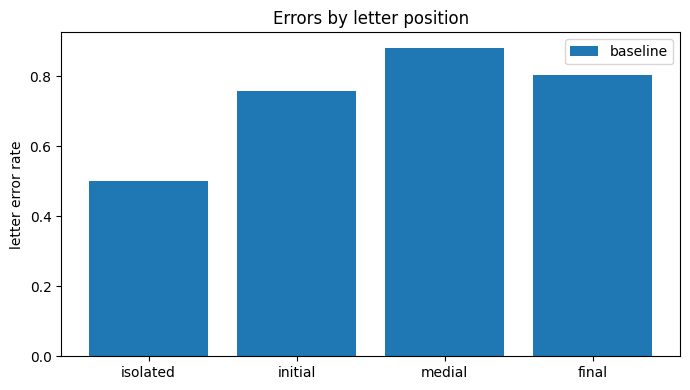

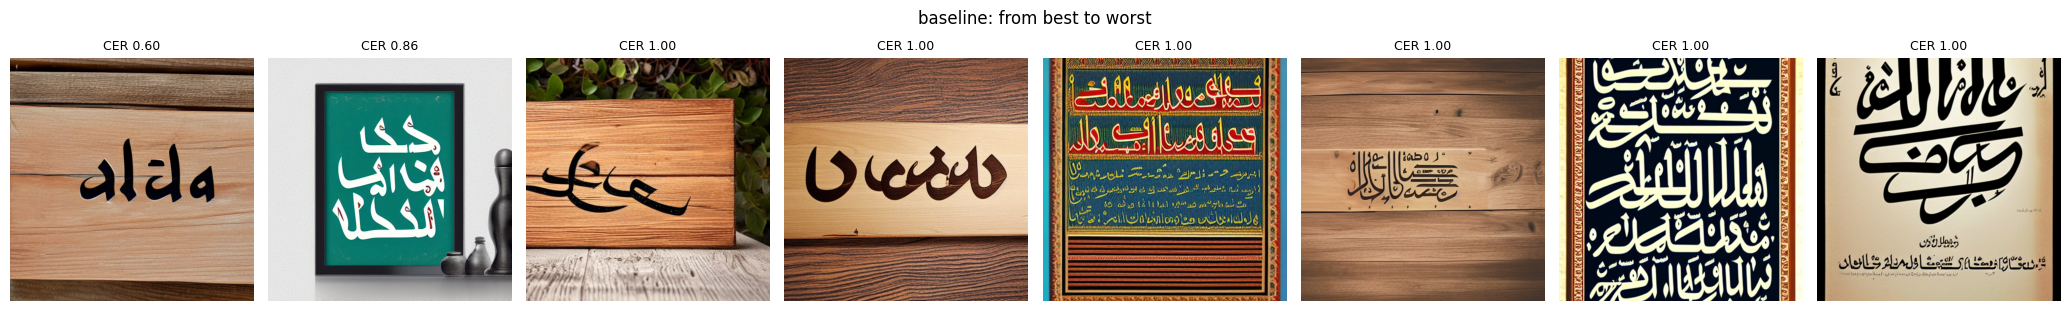

In [33]:
def plot_positions(dfs, labels):
    forms = ['isolated', 'initial', 'medial', 'final']
    x = np.arange(len(forms)); w = 0.8 / len(dfs)
    plt.figure(figsize=(7, 4))
    for k, (df, lab) in enumerate(zip(dfs, labels)):
        vals = [df[f'err_{f}'].sum() / max(df[f'tot_{f}'].sum(), 1) for f in forms]
        plt.bar(x + k * w, vals, w, label=lab)
    plt.xticks(x + w * (len(dfs) - 1) / 2, forms); plt.ylabel('letter error rate')
    plt.title('Errors by letter position'); plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, 'position_errors.png'), dpi=150); plt.show()

plot_positions([df_base], ['baseline'])

def show_examples(df, tag, n=8):
    sample = df.sort_values('cer').iloc[np.linspace(0, len(df) - 1, n).astype(int)]
    fig, axes = plt.subplots(1, n, figsize=(2.6 * n, 3.2))
    for ax, (_, r) in zip(axes, sample.iterrows()):
        ax.imshow(Image.open(os.path.join(OUT_DIR, tag, r.file))); ax.axis('off')
        ax.set_title(f"CER {r.cer:.2f}", fontsize=9)
    plt.suptitle(f'{tag}: from best to worst'); plt.tight_layout(); plt.show()

show_examples(df_base, 'baseline')

## Step 5. LoRA fine-tuning on rendered Arabic words

Training images are rendered words on varied backgrounds, colours, fonts and sizes, with the same kind of captions as the test prompts. Training words never appear in the test set, so the test measures whether the model learned Arabic script in general and not just memorised words.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


trainable parameters: 2184192


/tmp/ipykernel_353/4090031815.py:47: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


LoRA:   0%|          | 0/1500 [00:00<?, ?it/s]

step 250: loss 0.0127
step 500: loss 0.0112
step 750: loss 0.0104
step 1000: loss 0.0100
step 1250: loss 0.0113
step 1500: loss 0.0128


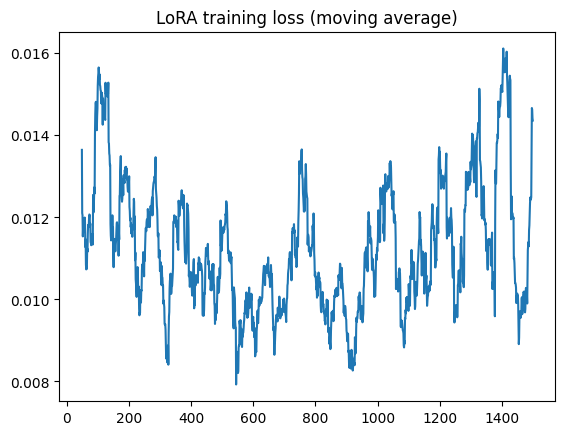

In [23]:
# Uninstall incompatible torchao version to resolve PEFT conflict
!pip uninstall -y torchao

from peft import LoraConfig, get_peft_model
from diffusers import DDPMScheduler

def random_training_image(word):
    bg = tuple(int(v) for v in np.random.randint(120, 256, 3))
    fg = tuple(int(v) for v in np.random.randint(0, 90, 3))
    if random.random() < 0.3:      # light text on a dark background
        bg, fg = tuple(255 - v for v in bg), tuple(255 - v for v in fg)
    img = render_word(word, random.choice(font_list), bg=bg, fg=fg,
                      font_px=int(IMG_SIZE * random.uniform(0.14, 0.26)))
    img = img.rotate(random.uniform(-6, 6), fillcolor=bg)
    if random.random() < 0.3:
        img = img.filter(ImageFilter.GaussianBlur(random.uniform(0, 1.0)))
    return img

def to_tensor(img):
    a = torch.from_numpy(np.array(img)).float().permute(2, 0, 1) / 127.5 - 1.0
    return a.unsqueeze(0)

unet, vae, text_encoder, tokenizer = pipe.unet, pipe.vae, pipe.text_encoder, pipe.tokenizer
noise_sched = DDPMScheduler.from_pretrained(MODEL_ID, subfolder='scheduler')
for m in (unet, vae, text_encoder):
    m.requires_grad_(False)

# Configure and apply LoRA adapters using get_peft_model explicitly
unet_config = LoraConfig(r=LORA_RANK, lora_alpha=LORA_RANK, init_lora_weights='gaussian',
                         target_modules=['to_q', 'to_k', 'to_v', 'to_out.0'])
unet = get_peft_model(unet, unet_config)

if TRAIN_TEXT_ENCODER:
    text_config = LoraConfig(r=LORA_RANK, lora_alpha=LORA_RANK, init_lora_weights='gaussian',
                             target_modules=['q_proj', 'k_proj', 'v_proj', 'out_proj'])
    text_encoder = get_peft_model(text_encoder, text_config)

params = [p for m in (unet, text_encoder) for p in m.parameters() if p.requires_grad]
for p in params:
    p.data = p.data.float()          # trainable LoRA weights in fp32, frozen weights stay fp16
print('trainable parameters:', sum(p.numel() for p in params))

# Use base_model.model to access gradient checkpointing on the wrapped UNet
unet.base_model.model.enable_gradient_checkpointing()
unet.train(); text_encoder.train(TRAIN_TEXT_ENCODER)
opt = torch.optim.AdamW(params, lr=LORA_LR, weight_decay=1e-2)
scaler = torch.cuda.amp.GradScaler()
losses = []
for step in tqdm(range(LORA_STEPS), desc='LoRA'):
    w = random.choice(TRAIN_WORDS)
    caption = random.choice(PROMPTS).format(w=w)
    x = to_tensor(random_training_image(w)).to(device, torch.float16)
    ids = tokenizer([caption], padding='max_length', max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors='pt').input_ids.to(device)
    with torch.autocast('cuda', dtype=torch.float16):
        with torch.no_grad():
            latents = vae.encode(x).latent_dist.sample() * vae.config.scaling_factor
        noise = torch.randn_like(latents)
        t = torch.randint(0, noise_sched.config.num_train_timesteps, (1,), device=device).long()
        noisy = noise_sched.add_noise(latents, noise, t)
        enc = text_encoder(ids)[0]
        pred = unet(noisy, t, encoder_hidden_states=enc).sample
        loss = torch.nn.functional.mse_loss(pred.float(), noise.float())
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
    scaler.step(opt); scaler.update()
    losses.append(loss.item())
    if (step + 1) % 250 == 0:
        print(f'step {step + 1}: loss {np.mean(losses[-250:]):.4f}')

unet.eval(); text_encoder.eval()
for p in params:
    p.data = p.data.half()           # back to fp16 so inference runs in one dtype
plt.plot(pd.Series(losses).rolling(50).mean()); plt.title('LoRA training loss (moving average)'); plt.show()

## Step 6. Evaluate the LoRA model on the same unseen words and seeds

In [34]:
df_lora = run_eval('lora')
lora_sum = summary(df_lora)
comparison = pd.DataFrame({'baseline': base_sum, 'LoRA': lora_sum})
comparison.to_csv(os.path.join(OUT_DIR, 'comparison.csv'))

# paired bootstrap on the CER difference (same words, prompts and seeds)
diff = df_lora.cer.values - df_base.cer.values
lo, hi = bootstrap_ci(diff)
print(f'CER change (LoRA - baseline): {diff.mean():+.3f} (95% CI {lo:+.3f} to {hi:+.3f})')
comparison.round(3)

lora:   0%|          | 0/60 [00:00<?, ?it/s]

CER change (LoRA - baseline): +0.000 (95% CI +0.000 to +0.000)


,baseline,LoRA
images,120.000,120.000
CER (mean),0.954,0.954
exact match %,0.000,0.000
no Arabic text %,18.333,18.333
Arabic-script ratio,0.703,0.703
substitutions / letter,0.460,0.460
deletions / letter,0.319,0.319
insertions / letter,1.830,1.830
dot errors (% of substitutions),5.590,5.590
CLIP score,0.343,0.343


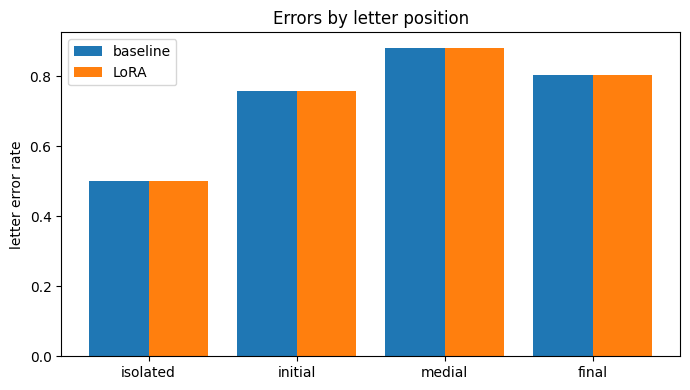

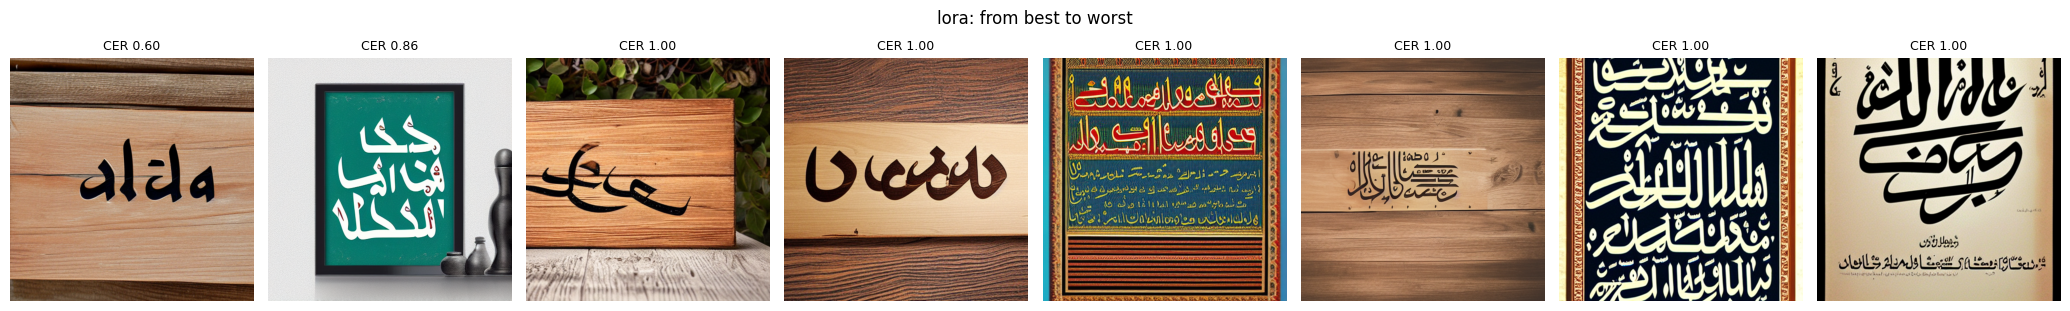

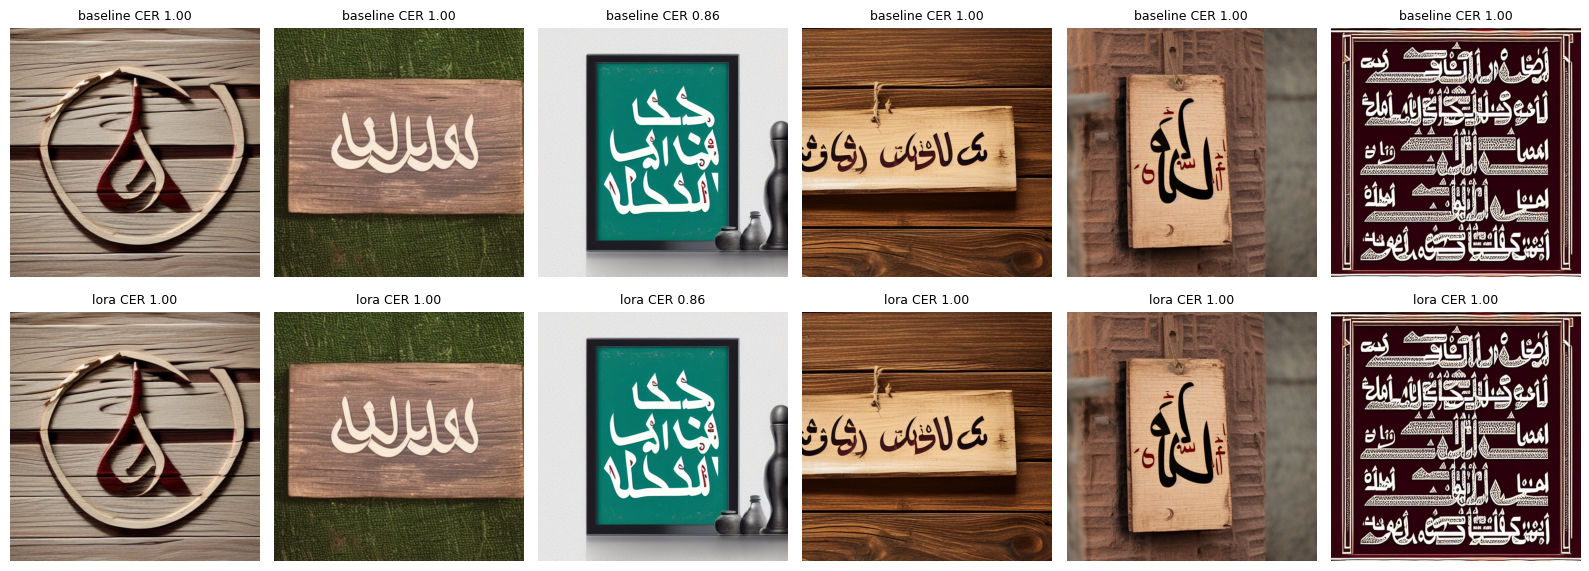

In [35]:
plot_positions([df_base, df_lora], ['baseline', 'LoRA'])
show_examples(df_lora, 'lora')

# side by side for the same words
idx = np.random.choice(len(df_base), 6, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for k, i in enumerate(idx):
    for row, (df, tag) in enumerate([(df_base, 'baseline'), (df_lora, 'lora')]):
        r = df.iloc[i]
        axes[row, k].imshow(Image.open(os.path.join(OUT_DIR, tag, r.file))); axes[row, k].axis('off')
        axes[row, k].set_title(f'{tag} CER {r.cer:.2f}', fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'side_by_side.png'), dpi=150); plt.show()

## Step 7. Save everything

The zip file contains all generated images, the CSV results, the plots and the LoRA weights.

In [36]:
from peft.utils import get_peft_model_state_dict
from safetensors.torch import save_file
sd = {f'unet.{k}': v for k, v in get_peft_model_state_dict(unet).items()}
if TRAIN_TEXT_ENCODER:
    sd.update({f'text_encoder.{k}': v for k, v in get_peft_model_state_dict(text_encoder).items()})
save_file({k: v.contiguous().cpu() for k, v in sd.items()}, os.path.join(OUT_DIR, 'arabic_glyph_lora.safetensors'))

import shutil
shutil.make_archive('/content/glyph_hallucination_results', 'zip', OUT_DIR)
print('Saved: /content/glyph_hallucination_results.zip')
try:
    from google.colab import files
    files.download('/content/glyph_hallucination_results.zip')
except Exception:
    pass

Saved: /content/glyph_hallucination_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes for writing up the results

* **OCR-verified words.** Every test word was read correctly by the OCR in clean renders, so errors in generated images are counted as diffusion errors. Report how many words passed this check.
* **Paired comparison.** Baseline and LoRA use the same words, prompts and seeds, so the CER difference and its bootstrap interval are a fair test.
* **Dot errors** are substitutions between letters that share a skeleton (for example س and ش). They are a script-specific kind of hallucination worth reporting on their own.
* **Position errors** show whether the model struggles more with initial, medial or final letter forms.
* **Limits.** One OCR engine, one base model (SD 1.5), and short single words. A next step is longer phrases, a second OCR engine, and newer models.